# AutoBio Notebook 05: A Dyna-Style Closed Loop for World-Gymnast

**在原有 Notebook05 上补充：GRPO 随机策略训练 → Simulator 采集 → latent dynamics 微调 → 再训练 → 真实配对评价。**

本 notebook 已实现并测试这套训练流程。当前环境已安装 CPU PyTorch 和 MuJoCo；原 Stage 4 权重、源码和任务资产尚未接入，因此本次保存的输出是历史核验、真实优化器的合成测试与资源检查。新的 AutoBio 成功率仍需原实验 bundle 才能测量。

沿用 11 月 4 日执行任务书的动作 likelihood、冻结参考策略、独立验证、真实反馈和同预算对照要求。早期的固定候选搜索/奖励修正仍保留在 `dyna05/core.py`，下文的训练入口使用新增的 GRPO 与 latent 参数更新。

[运行说明](docs/notebook05.md) · [GRPO](dyna05/grpo.py) · [Latent 微调](dyna05/latent.py) · [整轮执行](dyna05/training.py)

## 1. Goal — 从 9 次虚假成功开始

Notebook 04 比较的是同一个冻结控制器在两个反馈回路里的判断。90 次实际成功与 95 次预测成功之间，不只是 5 次的数量差异：10 次真实失败中，有 9 次被模型错判为成功。

先从保存的 **100 条历史配对记录**重新计算混淆矩阵。这个步骤不运行物理仿真。

In [1]:
from pathlib import Path
import json, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'dyna05').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'dyna05').is_dir(), 'Run this notebook from the repository root.'
sys.path.insert(0, str(ROOT))
from dyna05.audit import audit_stage4
from dyna05.assets import preflight
from dyna05.core import Config, generate_candidates, RewardCorrection, run_cycle

historical = audit_stage4(ROOT)
metrics = historical['metrics']
table = pd.DataFrame([[metrics['tp'], metrics['fn']], [metrics['fp'], metrics['tn']]],
                     index=['Simulator success', 'Simulator failure'],
                     columns=['Model success', 'Model failure'])
display(table)
print(f"Historical records: {metrics['n']}; checked files: {historical['checked_files']}.")
print(f"Failure recall: {metrics['failure_recall']:.1%}; false success among actual failures: {metrics['false_success_among_failures']:.1%}.")
print('New simulator runs in this cell: 0.')

Historical records: 100; checked files: 25.
Failure recall: 10.0%; false success among actual failures: 90.0%.
New simulator runs in this cell: 0.


,Model success,Model failure
Simulator success,86,4
Simulator failure,9,1


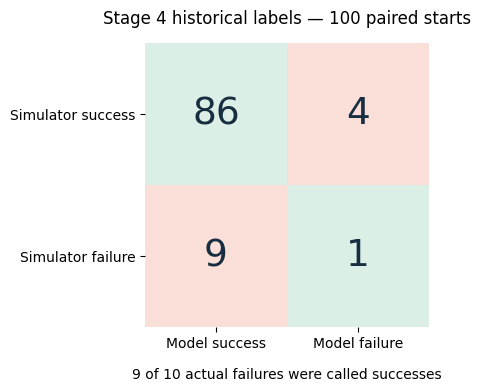

In [2]:
fig, ax = plt.subplots(figsize=(6.8, 3.8), constrained_layout=True)
values = table.to_numpy()
colors = np.array([[0., 1.], [1., 0.]])
from matplotlib.colors import ListedColormap
ax.imshow(colors, cmap=ListedColormap(['#dcefe7', '#f9dfd8']), vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(values[i, j]), ha='center', va='center', fontsize=27, color='#172d40')
ax.set_xticks([0, 1], ['Model success', 'Model failure'])
ax.set_yticks([0, 1], ['Simulator success', 'Simulator failure'])
ax.set_title('Stage 4 historical labels — 100 paired starts', pad=14)
ax.set_xlabel('9 of 10 actual failures were called successes', labelpad=12)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

## 2. 固定协议与数据划分

| 项目 | 定义 |
|---|---|
| π0 | 原 Stage 4 状态学生 `dense50_10000.pt`＋原 lift rule；保持冻结 |
| π_init | π0 上增加状态条件随机残差，尚未训练；单独评价以区分随机探索与学习收益 |
| π1 | 在 T0 中执行第一阶段 GRPO 后的策略 |
| π2 | 使用真实 Simulator 转移微调并验证模型，再进行相同预算 GRPO |
| frozen_T0 | 从同一 π1、optimizer、reference、RNG 出发，在旧 T0 中继续训练的对照 |
| 动作 | 原控制器消费 50×7 chunk，输出 10×7 物理命令包，每包 0.2 秒 |
| 时长与成功 | 112 包＝22.4 秒；同一 post-packet observation 中 height > 0.925 m 且 contact；实际标签来自 `task.check()` |

同一 seed 保存一次 MuJoCo integration snapshot，再用于各策略。模型只接收初始 observation，后续读取自己的预测状态。策略更新和模型选择均不能访问最终 test 状态。原训练/开发 seed 清单还必须与本次划分交叉检查。

In [3]:
from dataclasses import asdict
from dyna05.training import TrainingConfig
training_config = TrainingConfig(**json.loads((ROOT / 'configs/notebook05_training.json').read_text()))
training_config.check()
display(pd.DataFrame([{'split': name, 'states': len(seeds), 'first_seed': min(seeds), 'last_seed': max(seeds)}
                      for name, seeds in training_config.splits().items()]))
display(pd.DataFrame([training_config.budget()]))
print('Fixed budget; final model checks add 100 imagined episodes. No physical episode has run here.')

Fixed budget; final model checks add 100 imagined episodes. No physical episode has run here.


,split,states,first_seed,last_seed
0,grpo_train,4,11066000,11066003
1,wm_fit,4,11067000,11067003
2,wm_validate,4,11068000,11068003
3,confirm,4,11069000,11069003
4,test,10,11070000,11070009


,simulator_episodes,grpo_imagined_episodes,final_prediction_episodes,seconds_per_episode
0,86,144,100,22.4


## 3. 真正的 GRPO 更新

`ResidualPolicy` 用小型 MLP 把当前状态映射成六个关节的 Gaussian 均值。每个动作包采样一次残差，十条命令共享它；gripper 不变。先计算十条命令共同允许的残差区间，再做 tanh 变换，因此执行时不用截断随机动作。

$$u \sim \mathcal N(\mu_\theta(s),\sigma^2 I),\qquad \delta=c+h\tanh(u)$$

$$\log\pi_\theta(\delta\mid s)=\sum_{j:h_j>0}\left[\log\mathcal N(u_j;\mu_j,\sigma^2)-\log h_j-\log(1-\tanh^2 u_j)\right].$$

同一起点采样一组轨迹，用该组 **模型预测的 episode success** 计算标准化 advantage。它是 imagined reward，最终成绩由 Simulator 测量。

$$A_i=(r_i-\bar r)/\operatorname{std}(r),\qquad
L=-\mathbb E[\min(\rho_i A_i,\operatorname{clip}(\rho_i,1-\epsilon,1+\epsilon)A_i)]+\beta\,KL(\pi_\theta\|\pi_{ref}).$$

一包是一个随机决策，概率比是该包六维联合概率比。padding 被屏蔽，每条轨迹先按有效包数平均，再对轨迹平均。old log-prob 在采样时冻结；reference 始终是 π_init。全组奖励相同则 advantage=0；整批全相同时记录跳过，不虚构额外奖励。

下面只是验证公式的小例子，不是抓管实验。

In [4]:
import torch
from dyna05.grpo import group_advantages
example_rewards = torch.tensor([[0., 1., 1., 0.], [1., 1., 1., 1.]])
advantages, constant_groups = group_advantages(example_rewards)
display(pd.DataFrame({'example_rewards': example_rewards.tolist(), 'advantages': advantages.tolist(),
                      'constant_group': constant_groups.tolist()}))
print('Synthetic arithmetic example. GRPO tests below execute real backward()/Adam updates.')

Synthetic arithmetic example. GRPO tests below execute real backward()/Adam updates.


,example_rewards,advantages,constant_group
0,"[0.0, 1.0, 1.0, 0.0]","[-1.0, 1.0, 1.0, -1.0]",False
1,"[1.0, 1.0, 1.0, 1.0]","[0.0, 0.0, 0.0, 0.0]",True


## 4. 用真实状态转移更新 latent dynamics

`fit_dynamics` 只接受 `wm_fit` 的 Simulator 轨迹 `(state, action_packet, next_state, height, contact)`。从一个真实状态编码开始，在窗口内递归预测；未来真实状态只用作监督目标，不放回预测输入。

训练损失是：latent next-state MSE ＋归一化 decoded-state MSE ＋ height MSE（0.05 m 尺度）＋ contact BCE。默认训练 40 次，窗口长 3 包；冻结 encoder、normalizer，更新 bridge 明确列出的 transition/readout 参数。若没有任何 transition 参数改变，直接报错。

在独立 `wm_validate` 上计算一步损失、整段动作回放的多步误差和成功判断 FP/FN。只有一步损失下降、多步 state/height/contact 误差不升、FP/FN 均不升，才采用新模型；拒绝的权重和指标也保存。这个门槛是小样本工程选择规则，不是统计性能保证。

**接着从 π1 分成两路：**一路用选定的 T1 再训练；另一路用冻结 T0 做等量训练。两路初始权重、优化器、参考策略与随机数状态完全相同。最终分别比较 π0、π_init、π1、π2、frozen_T0。

## 5. 实际执行优化器与完整流程测试

测试包括精确动作概率、正负 advantage 的 clipping、padding、零方差组、reference 冻结、checkpoint 恢复、已知目标上的 GRPO 优化、latent 参数实际改变、独立验证拒绝路径、完整闭环，以及真实入口拒绝 synthetic simulator。

测试夹具明确标记为 `synthetic_test`，只用于验证实现；测试中的成功率不进入 AutoBio 实验结果。

In [5]:
check = subprocess.run([sys.executable, '-m', 'pytest', 'tests', '-q'], cwd=ROOT, capture_output=True, text=True)
print(check.stdout.strip())
if check.returncode:
    print(check.stderr[-4000:])
assert check.returncode == 0, 'Training or protocol verification failed.'

....................................................                     [100%]
52 passed in 4.17s


## 6. 检查原实验资源

需要 `dense50_10000.pt`、repair_v2 step 8000 权重、原 controller/encoder/dynamics/readout 与归一化、AutoBio 任务资产、完整训练/开发 seed 清单，以及适配这些实际类的 bridge。

bridge 新增 `trainable_model`：真实原模型的 `torch.nn.Module` 包装，提供可微 `encode/transition/decode`。训练前会核对它和原 `world_model` 的递归预测是否一致。没有原源码时，不能从 128 维历史 latent 输出猜一个架构来代替。

In [6]:
import mujoco
ASSETS = ROOT / 'configs/notebook05_assets.example.json'
availability = preflight(ASSETS)
print('Installed:', {'torch': torch.__version__, 'mujoco': mujoco.__version__})
print('AutoBio execution status:', availability['status'])
display(pd.DataFrame({'missing prerequisite': availability['blockers']}))

Installed: {'torch': '2.6.0+cpu', 'mujoco': '3.3.0'}
AutoBio execution status: BLOCKED


,missing prerequisite
0,policy_checkpoint: path not supplied
1,world_model_checkpoint: path not supplied
2,state_action_schema: path not supplied
3,training_seed_manifest: path not supplied
4,bridge_source: path not supplied
5,Original Stage 4 controller/model class defini...


## 7. 执行一轮并读取真实对照结果

补全实际资源 manifest 后，改 `ASSETS` 路径并重跑上一个 cell，再开启 `RUN_REAL`。训练过程保存 checkpoints、optimizer/RNG、实际与模型轨迹、模型验证、独立 confirm 选策、最终逐例标签与配对统计。

confirm 只在真实成功次数严格增加时选用新策略；test 首次运行前冻结该选择。最终报告保留所有策略结果，不按 test 分数重新选策。十个最终起点只能提供小规模配对证据；即使提升，也需要后续扩大独立评价。

In [7]:
RUN_REAL = False
OUTPUT = ROOT / 'runs/notebook05_grpo_round1'
if RUN_REAL:
    assert not availability['blockers'], 'Supply the original Stage 4 bundle first.'
    command = [sys.executable, '-m', 'dyna05.cli', 'train', '--assets', str(ASSETS),
               '--config', str(ROOT / 'configs/notebook05_training.json'), '--output', str(OUTPUT)]
    subprocess.run(command, cwd=ROOT, check=True)
    result = json.loads((OUTPUT / 'result.json').read_text())
    assert result['status'] == 'COMPLETE' and result['evidence_kind'] == 'mujoco'
    display(pd.DataFrame([{'policy': name, **values} for name, values in result['policy_comparisons'].items()]))
    display(pd.DataFrame([{'policy': name, 'model': version, **values}
                         for name, versions in result['heldout_model_errors'].items()
                         for version, values in versions.items()]))
    display(pd.DataFrame([result['model_update_vs_extra_training']]))
    print('Selected on confirmation states:', result['selection']['selected_policy'])
    print('Actual optimizer steps:', result['grpo_optimizer_steps'])
    print('Latent update accepted:', result['model_dynamics_update_selected'])
else:
    print('New AutoBio simulator episodes: 0. Before/after real success rates are awaiting the original assets.')

New AutoBio simulator episodes: 0. Before/after real success rates are awaiting the original assets.


## 8. 本轮交付

GRPO、原 latent 模型可微接口与微调器、两阶段训练、冻结旧模型的等预算对照、固定初始状态的实际评价，均已写入并通过独立测试。保留既有 Notebook05，不新增 notebook。

本次还没有原抓管任务的新实验结果。接入资源后，`train` 命令执行完整流程；以 `result.json` 的 **Simulator 配对结果**回答策略有没有改善，以独立模型验证与最终 FP/FN 回答模型有没有改善。若梯度因全组同奖而为零，或模型验证不通过，报告会如实记录，而不会把“运行完成”当成性能提升。